# Detect differential item functioning with TIRT

**Experimental.** The DIF API and defaults may change.

A group can differ in average ability, in how a comparison works at the same
ability, or both. In this example some comparison cutpoints differ between
groups (uniform DIF) and some statement loadings differ (nonuniform DIF).
[Lee et al. (2021)](https://doi.org/10.1177/1094428120959822) investigated both
types of DIF with a TIRT model for three-statement blocks. Here we use
two-statement blocks to illustrate the two effects.

## Model

For person $i$ in group $g$ and pair $j$, the probability of choosing
the first statement is
$$
P(Y_{ij}=1\mid\theta_i,g)=
\Phi\bigl(k_{j1}a_{j1g}\theta_{it_1}-k_{j2}a_{j2g}\theta_{it_2}
+u_{j1}-u_{j2}-b_j-\delta_{jg}\bigr).
$$
Here $k$ is statement keying, $a$ is positive loading magnitude,
$t$ selects the measured trait, and $u$ is the statement effect.
The baseline cutpoint is $b_j$ and its group offset is $\delta_{jg}$.
The comparison residual variance is one.

### Identification

Each pair compares two different traits. The design uses all three possible
trait pairings with mixed statement keying. This structure lets the model
estimate the statement loadings without fixing any to known values.
See
[Brown and Maydeu-Olivares (2012, Example 3)](https://www.ub.edu/gdne/documents/BRM_Fitting_TIRT.pdf).

The reference group's trait means are zero. Both groups have unit residual
trait SDs and share an estimated trait correlation matrix. The focal group's
means are estimated. We assume that DIF is sparse and shrink group differences
in measurement parameters toward zero. This lets the majority of comparisons
inform the group mean difference. For the use of sparsity in DIF analysis
without prespecified anchors, see
[Chen et al. (2023)](https://doi.org/10.1007/s11336-023-09930-9).

In [1]:
import arviz_stats as azs
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import pyfcirt as fc

## Generate one dataset

Simulate 800 people, split equally between groups A and B, answering 12 pairs.
The pairs cover T1/T2, T2/T3 and T1/T3 four times each. Group B has trait mean
shifts of 0.45, -0.30 and 0.20. Its cutpoints shift by +1.50, -1.50 and +1.50 in
B02, B06 and B10, respectively.

In group B, statement B03_1 changes loading magnitude from 0.90 to 0.45,
and B07_1 changes from 0.90 to 1.80. All other generating loadings are
shared. Generating statement effects are zero. The model allows each
of the 24 loadings and 12 cutpoints to vary across groups.

In [2]:
rng = np.random.default_rng(730026)
n = 800
blocks = [f"B{i:02d}" for i in range(1, 13)]
traits = np.tile([(0, 1), (1, 2), (0, 2)], (4, 1))
group = rng.permutation(np.repeat([0, 1], n // 2))
people = pd.DataFrame({"person_id": np.arange(n), "site": np.where(group, "B", "A")})
people["site"] = pd.Categorical(people["site"], categories=["A", "B"])
correlation = [[1, 0.35, -0.15], [0.35, 1, 0.25], [-0.15, 0.25, 1]]
theta = rng.multivariate_normal([0, 0, 0], correlation, size=n)
theta += group[:, None] * np.array([0.45, -0.30, 0.20])

loadings = np.tile([0.9, 1.1], (len(blocks), 1))
keying = np.tile([1, -1], (len(blocks), 1))
keying[[1, 3, 5, 7, 9, 11], 1] = 1
design = pd.DataFrame(
    [
        (block, j + 1, f"{block}_{j + 1}", f"T{traits[k, j] + 1}", keying[k, j])
        for k, block in enumerate(blocks)
        for j in (0, 1)
    ],
    columns=["block_id", "position", "statement_id", "trait", "keying"],
)
cutpoint_shift = np.zeros(len(blocks))
cutpoint_shift[[1, 5, 9]] = [1.5, -1.5, 1.5]
loading_shift = np.zeros_like(loadings)
loading_shift[[2, 6], 0] = [-0.45, 0.90]
person_loadings = loadings + group[:, None, None] * loading_shift
utility = (theta[:, traits] * person_loadings * keying) @ np.array([1, -1])
threshold = np.linspace(-0.5, 0.5, len(blocks)) + group[:, None] * cutpoint_shift
choices = (utility + rng.normal(size=threshold.shape) >= threshold).astype(int)
responses = pd.DataFrame(
    {
        "person_id": np.repeat(people.person_id.to_numpy(), len(blocks)),
        "block_id": np.tile(blocks, n),
        "response": choices.ravel(),
    }
)
responses.head()

,person_id,block_id,response
0,0,B01,0
1,0,B02,0
2,0,B03,1
3,0,B04,1
4,0,B05,0


## Fit each DIF prior to the same choices

Apply the three priors to both cutpoints and free statement loadings. The
hierarchical prior shrinks each group effect toward zero. Pairwise L1
shrinks the absolute group difference. Truncated L1 caps that penalty and
adds a normal base distribution. The loading effects are estimated on the
log scale, preserving a positive loading magnitude.

Install the NumPyro extra to run these fits. See
[estimation backends](../examples/estimation_backends.md#calibrate-with-nuts).

In [3]:
specification = fc.TIRT(residuals="fixed")
inputs = fc.FCInput(
    design,
    fc.ResponseTable(responses, format="block_long"),
    model=specification,
    response_format=None,
    scale=fc.CategoryScale((0, 1)),
)
population = fc.PopulationSpec(
    group="site",
    reference_group="A",
    theta_correlation="shared",
)
priors = {
    "Hierarchical": "hierarchical",
    "Pairwise L1": "pairwise_l1",
    "Truncated L1": "truncated_l1",
}
fits, diagnostics = {}, []
for label, prior in priors.items():
    model = fc.Model().prepare(
        inputs, person_data=people, population=population, theta_parameterization="noncentered"
    )
    model.add_dif_terms(
        ["fc.cutpoints", "fc.loading_magnitude"],
        person_data=people,
        groups="site",
        prior=prior,
    )
    idata = model.fit(
        draws=1000,
        tune=1200,
        chains=4,
        random_seed=33,
        nuts_sampler="numpyro",
        progressbar=False,
    )
    fits[label] = model
    variables = [
        "cutpoint",
        "loading",
        "regression_coefficient",
        "theta",
        "population_mean",
        "trait_correlation",
    ]
    rhat = azs.rhat(idata.posterior.dataset[variables])
    diagnostics.append(
        {
            "Prior": label,
            "Maximum R-hat": max(float(rhat[name].max()) for name in rhat),
            "Divergences": int(idata.sample_stats.dataset.diverging.sum()),
        }
    )
pd.DataFrame(diagnostics).round(3)

,Prior,Maximum R-hat,Divergences
0,Hierarchical,1.015,0
1,Pairwise L1,1.012,0
2,Truncated L1,1.010,0


## Compare the cutpoints

Each row compares B with A. For the cutpoint, a positive difference means
respondents in group B need a larger utility advantage to choose the first
statement. Dots show posterior means, bars mark 95% equal-tailed credible
intervals, and diamonds show the generating differences.

All three priors recover the direction of the cutpoint shifts in B02, B06,
and B10. Their intervals exclude zero for those three pairs and include
zero for the other nine pairs.

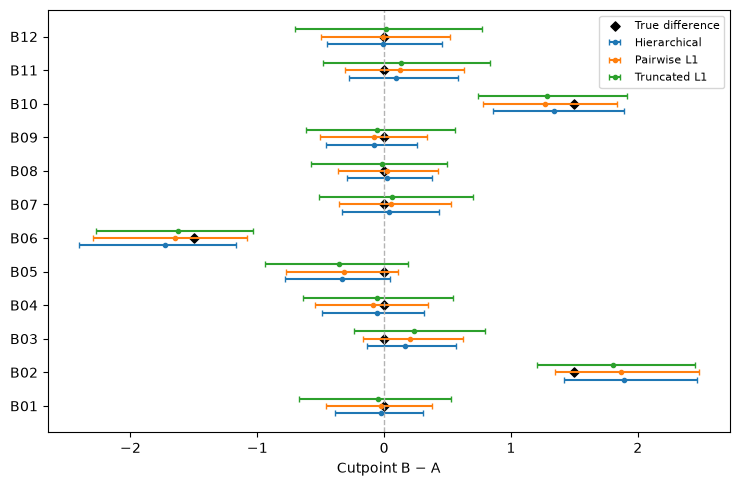

In [4]:
contrasts = pd.concat(
    [model.dif_summary({"site": ("A", "B")}).assign(Prior=label) for label, model in fits.items()],
    ignore_index=True,
)


def plot_contrasts(rows, label, truth, xlabel):
    labels = truth.index
    positions = np.arange(len(labels))
    fig, ax = plt.subplots(figsize=(7.5, max(2.8, 0.33 * len(labels) + 1)))
    groups = rows.groupby("Prior", sort=False)
    for offset, (name, values) in zip((-0.22, 0, 0.22), groups, strict=True):
        values = values.set_index(label).loc[labels]
        ax.errorbar(
            values["mean"],
            positions + offset,
            xerr=[values["mean"] - values.lower, values.upper - values["mean"]],
            fmt="o",
            ms=3,
            capsize=2,
            label=name,
        )
    ax.scatter(truth, positions, marker="D", s=22, c="black", label="True difference")
    ax.axvline(0, color="0.7", ls="--", lw=1)
    ax.set(yticks=positions, yticklabels=labels, xlabel=xlabel)
    ax.legend(loc="best", fontsize=8)
    fig.tight_layout()
    plt.show()


cutpoints = contrasts.loc[contrasts.parameter == "cutpoint"].copy()
cutpoints["Block"] = cutpoints.units.str[0]
plot_contrasts(cutpoints, "Block", pd.Series(cutpoint_shift, index=blocks), "Cutpoint B − A")

## Compare the statement loadings

The loading plot reports B minus A on the original loading magnitude scale.
A positive difference indicates a steeper statement utility slope in group B.
The plot shows both planted loading effects and two unchanged statements for
comparison. The summary also covers the other free loadings.

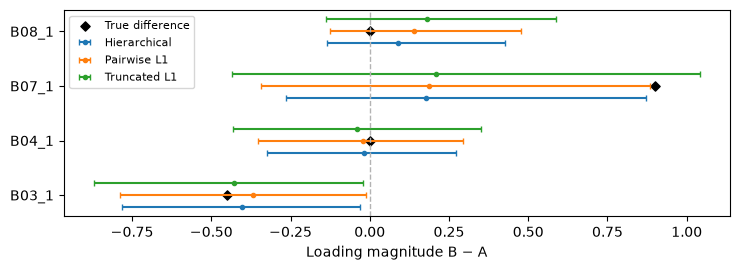

In [5]:
slopes = contrasts.loc[contrasts.parameter == "loading"]
truth = pd.Series(loading_shift.ravel(), index=design.statement_id)
selected = ["B03_1", "B04_1", "B07_1", "B08_1"]
plot_contrasts(slopes, "statement", truth.loc[selected], "Loading magnitude B − A")

All three priors detect the decrease for B03_1. For B07_1, each interval
includes zero despite a generating increase of 0.90. This example shows
how uncertain individual loading differences can be, even when the
cutpoint differences are clear.

The [DIF options](../reference/dif.md) describe
`model.dif_summary(significant_only=True)` and target-specific priors.